In [2]:
import sys
import os
import matplotlib.pyplot as plt
import numpy as np
sys.path.append('../../')
from utils_plots import apply_plot_style, get_layers, load_ii_curves, linestyle_for_language, _min_token_length
eps = 1E-7
colors, markers, _linestyles = apply_plot_style()
plot_id = 0
sys.path.append(os.path.expanduser('~/syn-sem'))
from modelpaths import get_model_depths
depths = get_model_depths()

/home/acevedo/venv/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [3]:
import numpy as np
import matplotlib.pyplot as plt

# -----------------------
# Config
# -----------------------
model = 'deepseek'
_model = 'deepseek'
model_title = 'DeepSeek-V3'

# model = "llama"
# _model = 'llama8b'
# model_title = 'Llama3-8b'

mask = 2
language_pairs = [
    # ("english", "spanish"),
    # ("german", "english"),
    ("english", "italian"),
    # ("english", "hungarian"),
]

n_files = 500
batch_size = 10
Ns = batch_size * n_files
batch_shuffle = 0

min_token_length = 40
avg_tokens_list = [0, 1]

k_II = 10
Nbits = 0
seeds_II = list(range(5))

n_tokens_list = [1, 20]
aux_A = "source"
aux_B = "target"

# Include concat+avg for n_tokens>1; for n_tokens=1 keep only avg_tokens=1.
condition_cases = [
    (n_tokens, avg_tokens)
    for n_tokens in n_tokens_list
    for avg_tokens in avg_tokens_list
    if not (n_tokens == 1 and avg_tokens == 0)
]
cond_to_id = {case: i for i, case in enumerate(condition_cases)}

layers = get_layers(_model, depths)
x = layers / depths[_model]


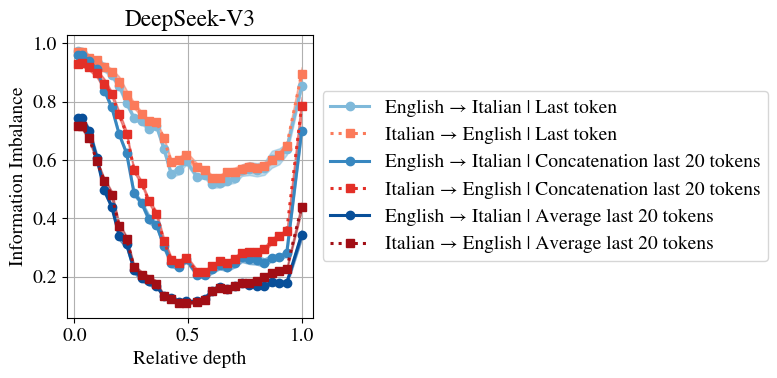

In [4]:
# Custom aesthetics: blue shades for A->B and red shades for B->A
for language_pair_id, (languageA, languageB) in enumerate(language_pairs):
    fig, ax = plt.subplots(1, 1, figsize=(8, 4))
    seen_labels = set()

    n_cond = len(condition_cases)
    blue_shades = plt.cm.Blues(np.linspace(0.45, 0.88, n_cond))
    red_shades = plt.cm.Reds(np.linspace(0.45, 0.88, n_cond))

    for n_tokens, avg_tokens in condition_cases:
        cond_id = cond_to_id[(n_tokens, avg_tokens)]

        mean_ii, std_ii = load_ii_curves(
            base="../results/santiago/",
            batch_shuffle=batch_shuffle,
            model=model,
            aux_A=aux_A,
            aux_B=aux_B,
            n_files=n_files,
            min_token_length=_min_token_length(model, languageA, languageB),
            languageA=languageA,
            languageB=languageB,
            mask=mask,
            k=k_II,
            Nbits=Nbits,
            seeds=seeds_II,
            n_tokens=n_tokens,
            avg_tokens=avg_tokens,
        )

        ls = _linestyles[cond_id % len(_linestyles)]

        color_AB = blue_shades[cond_id]
        color_BA = red_shades[cond_id]

        label_AB_base = f"{languageA.title()} → {languageB.title()}"
        label_BA_base = f"{languageB.title()} → {languageA.title()}"

        if n_tokens == 1:
            cond_label = "Last token"
        elif avg_tokens == 0:
            cond_label = f"Concatenation last {n_tokens} tokens"
        else:
            cond_label = f"Average last {n_tokens} tokens"

        label_AB = f"{label_AB_base} | {cond_label}"
        label_BA = f"{label_BA_base} | {cond_label}"

        use_label = label_AB if label_AB not in seen_labels else None
        ax.plot(x, 
                mean_ii[0], 
                label=use_label, 
                linestyle='-', 
                color=color_AB, 
                marker="o", 
                linewidth=2.2)
        if use_label:
            seen_labels.add(label_AB)
        ax.fill_between(x, mean_ii[0] - std_ii[0], mean_ii[0] + std_ii[0], alpha=0.5, color=color_AB)

        use_label = label_BA if label_BA not in seen_labels else None
        ax.plot(x, 
                mean_ii[1], 
                label=use_label, 
                linestyle='dotted', 
                color=color_BA, 
                marker="s", 
                linewidth=2.2)
        if use_label:
            seen_labels.add(label_BA)
        ax.fill_between(x, mean_ii[1] - std_ii[1], mean_ii[1] + std_ii[1], alpha=0.5, color=color_BA)

    ax.set_xlabel("Relative depth")
    ax.set_ylabel("Information Imbalance")
    ax.grid()

    box = ax.get_position()
    ax.set_position([box.x0, box.y0, box.width * 1, box.height])
    ax.legend(loc="center left", bbox_to_anchor=(1, 0.5))

    ax.set_title(model_title)
    fig.savefig(fname=f'../results/figs/last-concat-avg_{model}_{languageB}_blue-red-shades.pdf', bbox_inches='tight')
    plt.show()


In [5]:
# np.savetxt('deepseek-layer-dependence-mean.txt',mean_ii.T)
# np.savetxt('deepseek-layer-dependence-std.txt',std_ii.T)

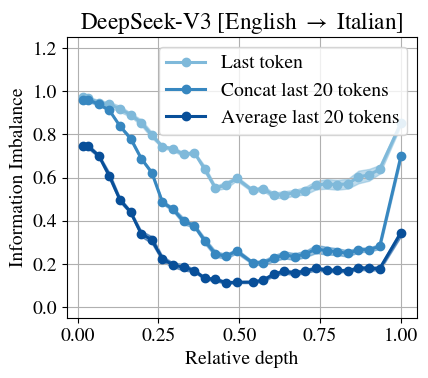

In [6]:
# Custom aesthetics: blue shades for A->B and red shades for B->A
for language_pair_id, (languageA, languageB) in enumerate(language_pairs):
    fig, ax = plt.subplots(1, 1, figsize=(4.5, 4))
    seen_labels = set()

    n_cond = len(condition_cases)
    blue_shades = plt.cm.Blues(np.linspace(0.45, 0.88, n_cond))
    red_shades = plt.cm.Reds(np.linspace(0.45, 0.88, n_cond))

    for n_tokens, avg_tokens in condition_cases:
        cond_id = cond_to_id[(n_tokens, avg_tokens)]

        mean_ii, std_ii = load_ii_curves(
            base="../results/santiago/",
            batch_shuffle=batch_shuffle,
            model=model,
            aux_A=aux_A,
            aux_B=aux_B,
            n_files=n_files,
            min_token_length=_min_token_length(model, languageA, languageB),
            languageA=languageA,
            languageB=languageB,
            mask=mask,
            k=k_II,
            Nbits=Nbits,
            seeds=seeds_II,
            n_tokens=n_tokens,
            avg_tokens=avg_tokens,
        )

        ls = _linestyles[cond_id % len(_linestyles)]

        color_AB = blue_shades[cond_id]
        color_BA = red_shades[cond_id]

        label_AB_base = f"{languageA.title()} → {languageB.title()}"
        label_BA_base = f"{languageB.title()} → {languageA.title()}"

        if n_tokens == 1:
            cond_label = "Last token"
        elif avg_tokens == 0:
            cond_label = f"Concat last {n_tokens} tokens"
        else:
            cond_label = f"Average last {n_tokens} tokens"

        label_AB = f"{cond_label}"
        label_BA = f"{cond_label}"

        use_label = label_AB if label_AB not in seen_labels else None
        ax.plot(x, 
                mean_ii[0], 
                label=use_label, 
                linestyle='-', 
                color=color_AB, 
                marker="o", 
                linewidth=2.2)
        if use_label:
            seen_labels.add(label_AB)
        ax.fill_between(x, mean_ii[0] - std_ii[0], mean_ii[0] + std_ii[0], alpha=0.5, color=color_AB)

        # use_label = label_BA if label_BA not in seen_labels else None
        # ax.plot(x, 
        #         mean_ii[1], 
        #         label=use_label, 
        #         linestyle='dotted', 
        #         color=color_BA, 
        #         marker="s", 
        #         linewidth=2.2)
        # if use_label:
        #     seen_labels.add(label_BA)
        # ax.fill_between(x, mean_ii[1] - std_ii[1], mean_ii[1] + std_ii[1], alpha=0.5, color=color_BA)

    ax.set_xlabel("Relative depth")
    ax.set_ylabel("Information Imbalance")
    ax.grid()

    # box = ax.get_position()
    # ax.set_position([box.x0, box.y0, box.width * 1, box.height])
    # ax.legend(loc="center left", bbox_to_anchor=(1, 0.5))
    ax.legend()
    ax.set_ylim(-0.05,1.25)

    ax.set_title(model_title + r' [English $\rightarrow$ Italian]')
    fig.savefig(fname=f'../results/figs/last-concat-avg_{model}_{languageB}_blue-shades.pdf', bbox_inches='tight')
    plt.show()